# Numerical Calculus: Accuracy, Resolution, and Computational Cost

## 1. Problem formulation
How can we choose a numerical method and sampling resolution to estimate rates of change and accumulated quantities accurately?

This report compares forward and central differences for derivatives, and composite left rectangles and trapezoids for definite integrals. A practical example estimates velocity from position and distance from velocity. Analytical benchmarks make approximation errors observable.

**Objectives:** implement the formulas directly, validate them, measure error over multiple resolutions, compare convergence and function-evaluation cost, and explain limitations.

**Hypotheses:** for sufficiently smooth functions, central differences have second-order truncation error whereas forward differences have first-order error; composite trapezoids generally converge quadratically whereas left rectangles converge linearly. Making a derivative step arbitrarily small will eventually encounter floating-point limitations.

**Assumptions:** deterministic scalar real-valued functions, uniform grids, finite intervals, float64 arithmetic, and smoothness where theoretical orders are invoked. No claim is made that this benchmark set represents all functions. The project is an algorithm implementation and analysis with a small mechanics application.


In [1]:
from pathlib import Path
import csv
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

OUTPUT = Path("results")
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "Matplotlib:", matplotlib.__version__)
print("float64 machine epsilon:", np.finfo(np.float64).eps)


def save_rows(filename, rows):
    with (OUTPUT / filename).open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def finish_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT / name, dpi=160, bbox_inches="tight")
    plt.show()


Python: 3.14.6
NumPy: 2.4.6 Matplotlib: 3.11.0
float64 machine epsilon: 2.220446049250313e-16


## 2. Mathematical derivation: differentiation
Taylor expansion about $x$ gives
$$f(x+h)=f(x)+hf'(x)+\frac{h^2}{2}f''(x)+O(h^3).$$
Subtracting $f(x)$ and dividing by $h$ yields
$$D_f(h)=\frac{f(x+h)-f(x)}h=f'(x)+\frac h2 f''(x)+O(h^2).$$
Expanding at both $+h$ and $-h$ and subtracting cancels the even powers:
$$D_c(h)=\frac{f(x+h)-f(x-h)}{2h}=f'(x)+\frac{h^2}{6}f^{(3)}(x)+O(h^4).$$
The displayed central remainder assumes sufficient smoothness for those Taylor terms. Bounded third derivatives already give an $O(h^2)$ truncation bound. See the general differentiation formulas in reference [1].

Finite precision introduces another effect: subtracting nearly equal function values loses relative precision. A simplified absolute-error model is $C_t h^p+C_r\epsilon/h$, with method- and function-dependent constants. Balancing terms suggests scales $\sqrt{\epsilon}$ for forward differences and $\epsilon^{1/3}$ for central differences when problem scales are near one. These are guidelines, not universal optimal steps. Reference [3] documents machine epsilon.

Both methods use two scalar function evaluations per estimate. Central differences require samples on both sides of the point and may be unsuitable at a domain boundary. Alternatives include higher-order finite differences, automatic differentiation, and symbolic differentiation; they are outside this comparison.


In [2]:
from numerical_methods import forward_difference, central_difference

## 3. Mathematical derivation: integration
For $n$ intervals on $[a,b]$, let $h=(b-a)/n$ and $x_i=a+ih$. Replacing each interval by its left endpoint height gives
$$L_n=h\sum_{i=0}^{n-1}f(x_i).$$
If $|f'|\le M_1$, each interval has error at most $M_1h^2/2$; summing gives $|I-L_n|\le (b-a)M_1h/2$ for $a<b$.

Integrating the straight line joining consecutive endpoints gives the composite trapezoid rule:
$$T_n=h\left[\frac{f(a)+f(b)}2+\sum_{i=1}^{n-1}f(x_i)\right].$$
For $f\in C^2[a,b]$ and $|f''|\le M_2$,
$$|I-T_n|\le\frac{b-a}{12}h^2 M_2.$$
Reference [2] supplies the trapezoid error formula. The integral is signed, not always geometrical area.

Rectangles use $n$ sampled values and trapezoids $n+1$. Both implementations take $O(n)$ work and $O(n)$ array memory. Their fair comparison therefore includes function-evaluation counts, not only interval counts. We count sampled scalar values even when NumPy evaluates an array in a single call. Simpson and adaptive quadrature are useful alternatives but outside the chosen scope.


In [3]:
from numerical_methods import left_rectangle, trapezoid

## 4. Validation before experiments
Checks include exactness for constants and affine functions, a known quadratic integral, reversed and zero-length bounds, and rejected invalid inputs. Assertions test independently known results rather than reimplementing the formulas as tests. No library quadrature routine is used as the only reference.


The algorithms live in `numerical_methods.py` so the notebook and standalone unit tests exercise the same implementation. Invalid steps, non-finite samples, incompatible output shapes, and unresolvable sampling grids are rejected explicitly. Integration callables must accept NumPy arrays; scalar constant outputs are supported. Run `python -m unittest discover -s tests -v` for independent regression checks.

In [4]:
def expect_value_error(action):
    try:
        action()
    except ValueError:
        return
    raise AssertionError("Expected ValueError")


for method in (forward_difference, central_difference):
    assert np.isclose(method(lambda x: 3*x + 2, 1.0, 0.01), 3)
    assert np.isclose(method(lambda x: 7, 2.0, 0.01), 0)
    expect_value_error(lambda: method(np.sin, 1.0, 0))
    expect_value_error(lambda: method(np.sin, 1.0, 1e-30))
assert np.isclose(central_difference(lambda x: x*x, 2.0, 0.01), 4)
for method in (left_rectangle, trapezoid):
    assert np.isclose(method(lambda x: 3, -1, 2, 10), 9)
    assert method(np.exp, 2, 2, 10) == 0
    expect_value_error(lambda: method(np.exp, 0, 1, 0))
    expect_value_error(lambda: method(np.exp, 0, 1, 2.5))
assert np.isclose(trapezoid(lambda x: 2*x+1, 0, 1, 5), 2)
assert np.isclose(trapezoid(lambda x: x*x, 0, 1, 1000), 1/3, atol=2e-7, rtol=0)
assert np.isclose(trapezoid(np.exp, 1, 0, 100), -trapezoid(np.exp, 0, 1, 100))
assert np.isclose(left_rectangle(lambda x: x, 1, 0, 100), -0.505)
print("All validation checks passed.")


All validation checks passed.


## 5. Derivative experiment: resolution and roundoff
Benchmarks are $e^x$ at 1, $\sin x$ at 0.7, and $x^3$ at 1.3. Their nonzero reference derivatives are $e$, $\cos(0.7)$, and $3(1.3)^2$. Each method uses the same 100 logarithmically spaced steps between $10^{-1}$ and $10^{-15}$. We report absolute error; no random sampling is involved.

The reference values are analytical expressions evaluated in float64, not arbitrary-precision truth. Errors near machine precision therefore reflect both approximation and reference rounding. Zero measured error does not prove mathematical exactness.


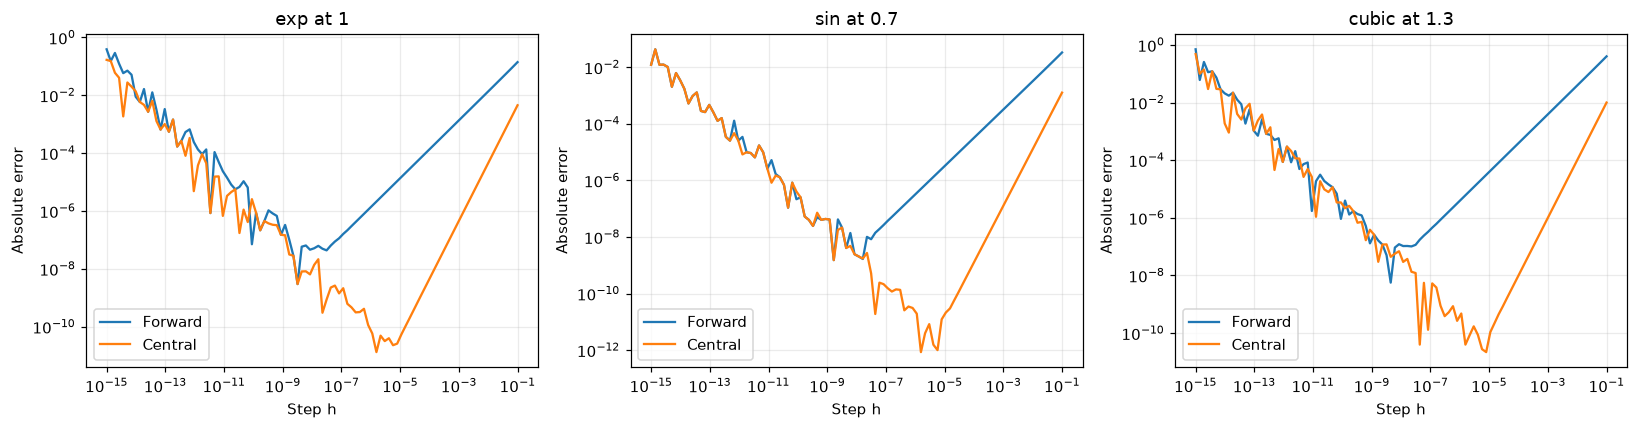

exp at 1        Forward  best sampled h=3.20e-09, error=2.97e-09
exp at 1        Central  best sampled h=1.56e-06, error=1.32e-11
sin at 0.7      Forward  best sampled h=1.67e-09, error=1.52e-09
sin at 0.7      Central  best sampled h=1.56e-06, error=8.52e-13
cubic at 1.3    Forward  best sampled h=4.43e-09, error=5.66e-09
cubic at 1.3    Central  best sampled h=7.92e-06, error=2.20e-11


In [5]:
derivative_cases = [
    ("exp at 1", np.exp, 1.0, np.exp(1.0)),
    ("sin at 0.7", np.sin, 0.7, np.cos(0.7)),
    ("cubic at 1.3", lambda x: x**3, 1.3, 3*1.3**2),
]
derivative_methods = [("Forward", forward_difference), ("Central", central_difference)]
steps = np.logspace(-1, -15, 100)
derivative_rows = []
best_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, function, point, reference) in zip(axes, derivative_cases):
    for method_name, method in derivative_methods:
        errors = np.array([abs(method(function, point, h) - reference) for h in steps])
        for h, error in zip(steps, errors):
            derivative_rows.append(dict(case=name, method=method_name, step=h, absolute_error=error))
        best = int(np.argmin(errors))
        best_rows.append(dict(case=name, method=method_name, step=steps[best], error=errors[best]))
        # Omit zero errors from logarithmic axes instead of inventing a positive error.
        ax.loglog(steps, np.where(errors > 0, errors, np.nan), label=method_name)
    ax.set(title=name, xlabel="Step h", ylabel="Absolute error")
    ax.legend()
finish_figure(fig, "derivative_errors.png")
save_rows("derivative_errors.csv", derivative_rows)
for row in best_rows:
    print(f"{row['case']:15} {row['method']:8} best sampled h={row['step']:.2e}, error={row['error']:.2e}")


### Measuring derivative convergence
If $E(h)\approx Ch^p$, fitting $\log E$ against $\log h$ estimates $p$. We choose $10^{-2}$ through $10^{-4}$ in advance to emphasize truncation rather than tiny-step roundoff. These fits are descriptive evidence on the selected range, not proofs or confidence intervals.


In [6]:
order_rows = []
fit_steps = np.logspace(-2, -4, 15)
for name, function, point, reference in derivative_cases:
    for method_name, method in derivative_methods:
        errors = np.array([abs(method(function, point, h) - reference) for h in fit_steps])
        slope = np.polyfit(np.log(fit_steps), np.log(errors), 1)[0]
        order_rows.append(dict(kind="derivative", case=name, method=method_name, measured_order=slope))
        print(f"{name:15} {method_name:8} estimated order={slope:.3f}")


exp at 1        Forward  estimated order=1.001
exp at 1        Central  estimated order=2.000
sin at 0.7      Forward  estimated order=1.001
sin at 0.7      Central  estimated order=2.000
cubic at 1.3    Forward  estimated order=1.000
cubic at 1.3    Central  estimated order=2.000


### 5.1 Richardson extrapolation: a fourth-order alternative
Write $D_c(h)=f'(x)+c_2h^2+c_4h^4+O(h^6)$. Combining two resolutions removes the $h^2$ term:
$$D_R(h)=\frac{4D_c(h/2)-D_c(h)}3=f'(x)-\frac{h^4}{480}f^{(5)}(x)+O(h^6).$$
This expansion assumes enough smoothness. Four sampled values are required instead of two. For cubic and quartic polynomials the truncation terms cancel exactly in exact arithmetic, so a measured convergence order would be misleading.

For exp and sin we fit fourth-order convergence on a coarser, preselected range h∈[0.03,0.3], before rounding dominates. The graph compares error for exp at 1; one Richardson estimate costs twice as many sampled values as a forward or central estimate. The extra precision is therefore not free.

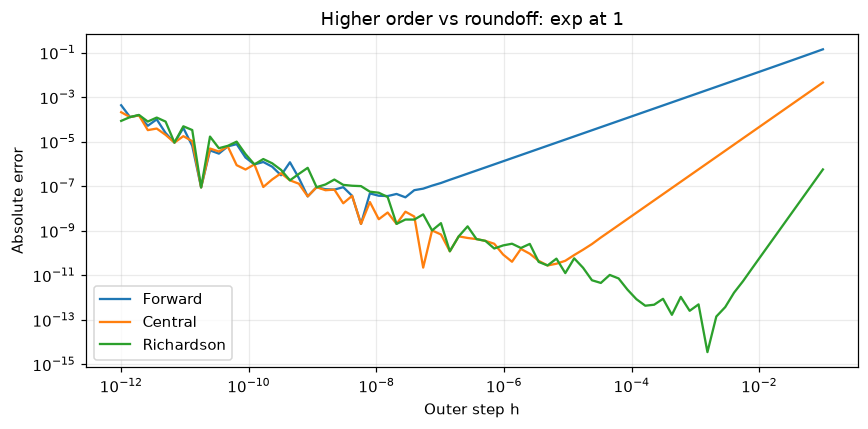

exp at 1: Richardson estimated order=4.001
sin at 0.7: Richardson estimated order=3.999


In [7]:
from numerical_methods import richardson_difference
richardson_steps = np.logspace(-1, -12, 80)
richardson_rows = []
fig, ax = plt.subplots(figsize=(8, 4))
for label, method in derivative_methods + [("Richardson", richardson_difference)]:
    errors = np.array([abs(method(np.exp, 1, h)-np.e) for h in richardson_steps])
    ax.loglog(richardson_steps, np.where(errors > 0, errors, np.nan), label=label)
    richardson_rows.extend(dict(method=label, step=h, absolute_error=e)
                           for h, e in zip(richardson_steps, errors))
ax.set(xlabel="Outer step h", ylabel="Absolute error", title="Higher order vs roundoff: exp at 1")
ax.legend()
finish_figure(fig, "richardson_errors.png")
save_rows("richardson_errors.csv", richardson_rows)
for name, function, point, reference in derivative_cases[:2]:
    hs = np.logspace(np.log10(0.3), np.log10(0.03), 15)
    errors = [abs(richardson_difference(function, point, h)-reference) for h in hs]
    slope = np.polyfit(np.log(hs), np.log(errors), 1)[0]
    assert 3.9 < slope < 4.1
    order_rows.append(dict(kind="derivative", case=name, method="Richardson", measured_order=slope))
    print(f"{name}: Richardson estimated order={slope:.3f}")
assert np.isclose(richardson_difference(lambda x: x**3, 1, 0.125), 3)


## 6. Integration experiment and sampling cost
Benchmarks are x² on [0,1], exp(x) on [0,1], and sin(x) on [0,π], with references 1/3, e−1, and 2. We use powers of two from 8 to 4096 intervals. Every experiment records its approximation, error, and number of sampled values. Theoretical error bounds are also checked using bounds on the first and second derivatives.


quadratic  Left       estimated order=1.000; final error=1.221e-04
quadratic  Trapezoid  estimated order=2.000; final error=9.934e-09
exp        Left       estimated order=1.000; final error=2.097e-04
exp        Trapezoid  estimated order=2.000; final error=8.535e-09
sin        Left       estimated order=2.000; final error=9.805e-08
sin        Trapezoid  estimated order=2.000; final error=9.805e-08


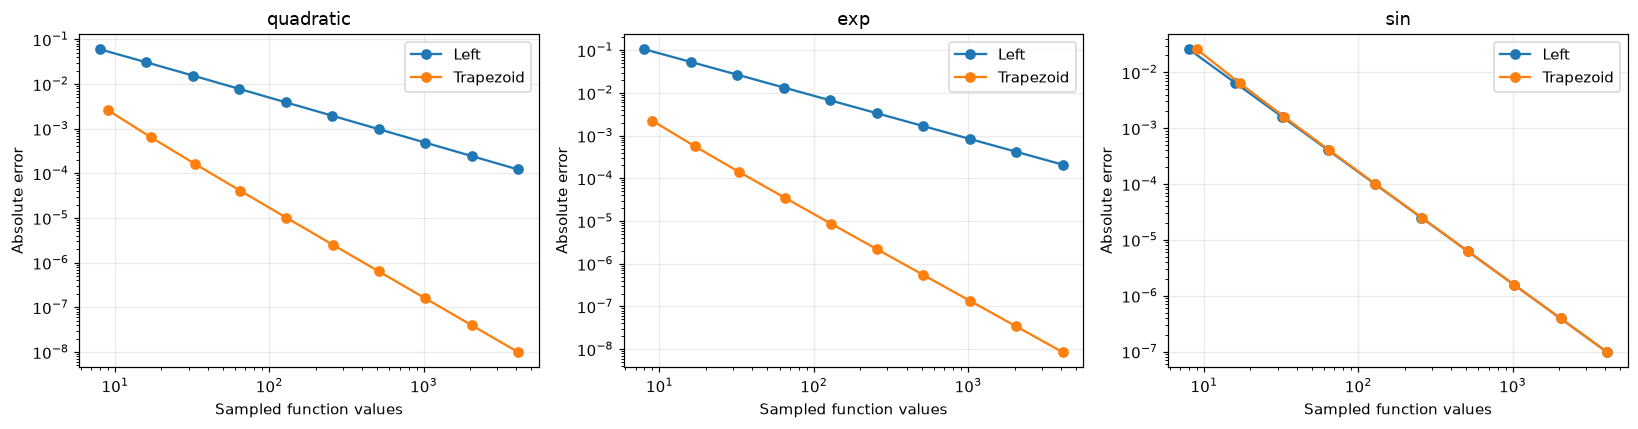

In [8]:
integral_cases = [
    ("quadratic", lambda x: x*x, 0.0, 1.0, 1/3, 2.0, 2.0),
    ("exp", np.exp, 0.0, 1.0, np.e-1, np.e, np.e),
    ("sin", np.sin, 0.0, np.pi, 2.0, 1.0, 1.0),
]
integral_methods = [("Left", left_rectangle), ("Trapezoid", trapezoid)]
counts = 2**np.arange(3, 13)
integral_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, function, a, b, reference, m1, m2) in zip(axes, integral_cases):
    for method_name, method in integral_methods:
        errors = []
        for count in counts:
            approximation = method(function, a, b, int(count))
            error = abs(approximation - reference)
            evaluations = int(count) + (method_name == "Trapezoid")
            integral_rows.append(dict(case=name, method=method_name, intervals=int(count),
                                      sampled_values=evaluations, approximation=approximation,
                                      absolute_error=error))
            errors.append(error)
            h = (b-a)/count
            bound = (b-a)*m1*h/2 if method_name == "Left" else (b-a)*m2*h*h/12
            assert error <= bound + 1e-12
        ax.loglog(counts + (method_name == "Trapezoid"), errors, "o-", label=method_name)
        slope = -np.polyfit(np.log(counts[-5:]), np.log(errors[-5:]), 1)[0]
        order_rows.append(dict(kind="integral", case=name, method=method_name, measured_order=slope))
        print(f"{name:10} {method_name:10} estimated order={slope:.3f}; final error={errors[-1]:.3e}")
    ax.set(title=name, xlabel="Sampled function values", ylabel="Absolute error")
    ax.legend()
finish_figure(fig, "integral_errors.png")
save_rows("integral_errors.csv", integral_rows)
save_rows("convergence_orders.csv", order_rows)


### An exception: symmetry changes the comparison
On [0,π], sin(x) has zero endpoint values. Therefore $T_n-L_n=h(f(b)-f(a))/2$ vanishes in exact arithmetic. Both methods return the same approximation even though their general error bounds have different orders. The measured second-order convergence of left rectangles here is a special cancellation, not a contradiction of its first-order general bound. In float64, sin(π) is only approximately zero.


In [9]:
for count in (8, 64, 512):
    assert np.isclose(left_rectangle(np.sin, 0, np.pi, count),
                      trapezoid(np.sin, 0, np.pi, count), atol=1e-14, rtol=0)
print("Endpoint-cancellation example verified.")


Endpoint-cancellation example verified.


## 7. Application: estimating velocity and distance
Consider a model position $s(t)=t^3$ metres for time in seconds on [0,2]. Velocity is $v(t)=3t^2$ m/s and acceleration is $6t$ m/s². We estimate velocity at t=1, then recover displacement by integrating velocity over [0,2]. Velocity is nonnegative, so displacement equals distance here. The exact distance is 8 m.

This is a controlled synthetic motion model, not experimental sensor data. It connects the numerical question to a practical rate/accumulation task while retaining a known answer.


Velocity at t=1, exact: 3 m/s
Forward estimate: 3.0301000000000133
Central estimate: 3.0001000000000055
n=  10: left=6.84000000 m; trapezoid=8.04000000 m; exact=8 m
n= 100: left=7.88040000 m; trapezoid=8.00040000 m; exact=8 m
n=1000: left=7.98800400 m; trapezoid=8.00000400 m; exact=8 m


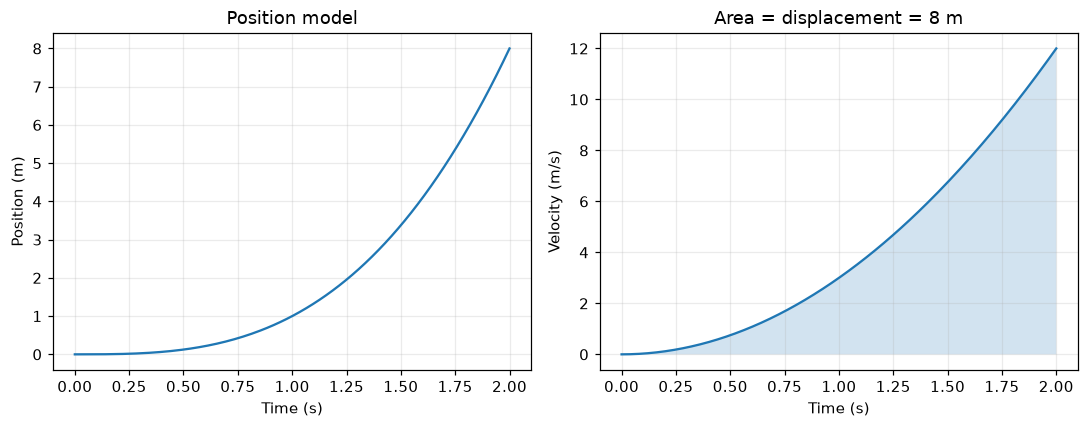

In [10]:
position = lambda t: t**3
velocity = lambda t: 3*t*t
print("Velocity at t=1, exact: 3 m/s")
print("Forward estimate:", forward_difference(position, 1.0, 0.01))
print("Central estimate:", central_difference(position, 1.0, 0.01))
application_rows = []
for count in (10, 100, 1000):
    left = left_rectangle(velocity, 0, 2, count)
    trap = trapezoid(velocity, 0, 2, count)
    application_rows.append(dict(intervals=count, left_distance=left, trapezoid_distance=trap,
                                 left_error=abs(left-8), trapezoid_error=abs(trap-8)))
    print(f"n={count:4}: left={left:.8f} m; trapezoid={trap:.8f} m; exact=8 m")
save_rows("motion_application.csv", application_rows)
t = np.linspace(0, 2, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(t, position(t))
axes[0].set(xlabel="Time (s)", ylabel="Position (m)", title="Position model")
axes[1].plot(t, velocity(t))
axes[1].fill_between(t, velocity(t), alpha=0.2)
axes[1].set(xlabel="Time (s)", ylabel="Velocity (m/s)", title="Area = displacement = 8 m")
finish_figure(fig, "motion_application.png")


## 8. Limitations: noisy samples and nonsmooth functions
Differentiation amplifies measurement noise. For independent additive sample errors with variance σ², the noise variance of a central difference is σ²/(2h²); shrinking h increases the noise contribution. This follows by adding the variances of the two sample errors and dividing by (2h)². The smooth deterministic experiments above do not quantify a complete sensor pipeline.

A second limitation is differentiability: applying the symmetric formula to abs(x) at zero returns zero for every positive step, even though the true derivative does not exist. Agreement across step sizes alone is insufficient validation. Integration convergence claims likewise require regularity; singular or discontinuous functions need separate treatment.


Symmetric estimate for abs at 0: 0.0
The one-sided slopes are -1 and +1, so the derivative does not exist.


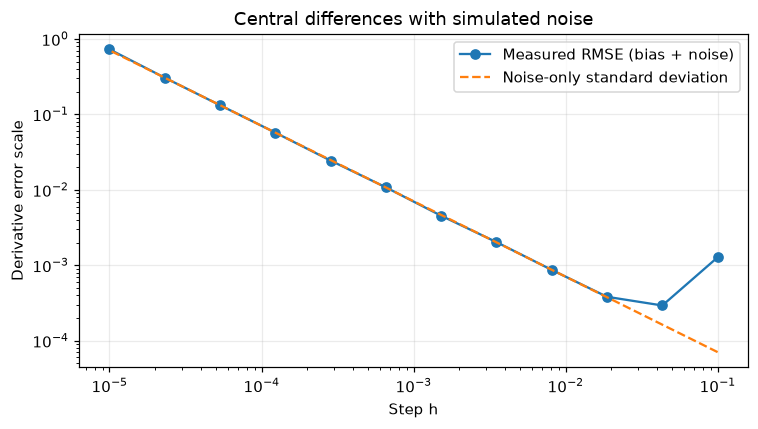

In [11]:
print("Symmetric estimate for abs at 0:", central_difference(np.abs, 0.0, 0.01))
print("The one-sided slopes are -1 and +1, so the derivative does not exist.")
# Fixed seed makes this additional noise experiment reproducible.
rng = np.random.default_rng(2026)
noise_steps = np.logspace(-1, -5, 12)
sigma = 1e-5
trials = 2000
rmse = []
for h in noise_steps:
    noise = rng.normal(0, sigma, size=(trials, 2))
    estimates = (np.sin(0.7+h) + noise[:, 0] - np.sin(0.7-h) - noise[:, 1]) / (2*h)
    rmse.append(np.sqrt(np.mean((estimates-np.cos(0.7))**2)))
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(noise_steps, rmse, "o-", label="Measured RMSE (bias + noise)")
ax.loglog(noise_steps, sigma/(np.sqrt(2)*noise_steps), "--", label="Noise-only standard deviation")
ax.set(xlabel="Step h", ylabel="Derivative error scale", title="Central differences with simulated noise")
ax.legend()
finish_figure(fig, "noise_sensitivity.png")
save_rows("noise_experiment.csv", [dict(step=h, rmse=e) for h, e in zip(noise_steps, rmse)])


## 9. Results summary
The table below is generated from the actual experiments, so it remains consistent when the notebook is rerun. Estimated orders use the fixed fitting ranges described above.


In [12]:
table = "| Experiment | Case | Method | Estimated order |\n|---|---|---|---:|\n"
for row in order_rows:
    table += f"| {row['kind']} | {row['case']} | {row['method']} | {row['measured_order']:.3f} |\n"
display(Markdown(table))
(OUTPUT / "measured_orders.md").write_text(table)


| Experiment | Case | Method | Estimated order |
|---|---|---|---:|
| derivative | exp at 1 | Forward | 1.001 |
| derivative | exp at 1 | Central | 2.000 |
| derivative | sin at 0.7 | Forward | 1.001 |
| derivative | sin at 0.7 | Central | 2.000 |
| derivative | cubic at 1.3 | Forward | 1.000 |
| derivative | cubic at 1.3 | Central | 2.000 |
| derivative | exp at 1 | Richardson | 4.001 |
| derivative | sin at 0.7 | Richardson | 3.999 |
| integral | quadratic | Left | 1.000 |
| integral | quadratic | Trapezoid | 2.000 |
| integral | exp | Left | 1.000 |
| integral | exp | Trapezoid | 2.000 |
| integral | sin | Left | 2.000 |
| integral | sin | Trapezoid | 2.000 |


671

## 10. Discussion and conclusion
The derivative experiment separates two regimes: truncation-dominated behavior at moderately small steps, followed by floating-point effects at very small steps. Over the chosen fitting range, central differences approach second-order behavior while forward differences approach first-order behavior. The smallest observed errors occur at different steps for different functions and methods. They are minima of the sampled grid, not globally optimized guarantees.

For the quadratic and exponential integration benchmarks, trapezoids approach second-order convergence and left rectangles first-order convergence. On the sine benchmark their endpoint weights cancel the difference between methods, so both converge quadratically. This exception demonstrates why comparisons should include multiple functions and a mathematical explanation rather than only a single favorable plot.

Both derivative schemes cost two evaluations, but central differences need access to both sides of the point. For integration, the trapezoid method uses one more sampled value at equal interval counts and usually achieves substantially smaller errors on the smooth nonsymmetric benchmarks. Timings are intentionally not used to claim speed improvements: interpreter overhead and vectorization can obscure algorithmic cost.

The motion example translates differentiation into velocity estimation and integration into accumulated displacement. Its analytical solution provides independent validation. The noisy-data experiment shows why reducing the step is not a universal solution, and abs(x) shows why smoothness must be checked before interpreting a finite-difference value as a derivative.

**Answer to the research question:** choose a method with suitable assumptions, verify it against known cases, and investigate error as resolution changes. For smooth interior points and smooth finite-interval integrals, central differences and trapezoids are strong baseline choices. Excessively small steps, noise, boundaries, and nonsmooth behavior require additional care.

**Further work:** adaptive quadrature, Simpson's rule, higher-precision references, unequal sampling, and methods designed for noisy measurements. These are proposed extensions and are not claimed as implemented.

## 11. References and assistance disclosure
1. NIST Digital Library of Mathematical Functions, [§3.4 Differentiation](https://dlmf.nist.gov/3.4): general numerical differentiation formulas and error structure. Accessed 24 October 2026.
2. NIST Digital Library of Mathematical Functions, [§3.5(i) Trapezoidal Rules](https://dlmf.nist.gov/3.5#i): composite trapezoid formula and smoothness-dependent error bound. Accessed 24 October 2026.
3. NumPy documentation, [numpy.finfo](https://numpy.org/doc/stable/reference/generated/numpy.finfo.html): floating-point machine limits and epsilon.
4. SoftUni, Math Concepts for Developers, September 2026: supplied Calculus lecture, exercise notebook, and Final Exam Project Guidelines. These motivated the topic; the numerical comparisons and application are organized specifically for this project.

Codex assisted with project structure, mathematical exposition, implementation, validation, and editing. The student must review and understand the submitted work and follow the course's assistance policy. The provided guidelines prohibit plagiarism but do not specify a separate AI policy; disclosure alone does not establish permission under any additional course rules. No human review or instructor approval is claimed here.
